# Credit Card Fraud Detection

## Project Overview

The goal of this project is to build a machine learning model that can identify fraudulent transactions.

The project goes through data understanding, preprocessing, EDA, feature engineering, model experiments, class imbalance handling, tuning, final evaluation, interpretation, and model saving.


## 1. Import Libraries


In [2]:
# Install required packages
%pip install pandas numpy matplotlib seaborn plotly scikit-learn imbalanced-learn catboost --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pickle

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

from imblearn.over_sampling import SMOTENC
from catboost import CatBoostClassifier



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Load the Dataset


In [3]:
df = pd.read_csv('fraud.csv')

## 3. Initial Data Understanding

I start by checking the dataset size, data types, duplicates, missing values, and unique values before making any changes.


In [4]:
df.shape

(594643, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  str    
 2   age          594643 non-null  str    
 3   gender       594643 non-null  str    
 4   zipcodeOri   594643 non-null  str    
 5   merchant     594643 non-null  str    
 6   zipMerchant  594643 non-null  str    
 7   category     594643 non-null  str    
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), str(7)
memory usage: 45.4 MB


### 3.1 Missing Values


In [6]:
df.isna().sum()


step           0
customer       0
age            0
gender         0
zipcodeOri     0
merchant       0
zipMerchant    0
category       0
amount         0
fraud          0
dtype: int64

In [7]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.nunique()

step             180
customer        4112
age                8
gender             4
zipcodeOri         1
merchant          50
zipMerchant        1
category          15
amount         23767
fraud              2
dtype: int64

In [10]:
for col in ['customer','age','gender','zipcodeOri','merchant','zipMerchant','category']:
  print(df[col].value_counts())


customer
'C1978250683'    265
'C1275518867'    252
'C806399525'     237
'C515668508'     205
'C1338396147'    195
                ... 
'C1156745710'      6
'C1345586046'      6
'C1743702978'      5
'C1404665203'      5
'C1809646275'      5
Name: count, Length: 4112, dtype: int64
age
'2'    187310
'3'    147131
'4'    109025
'5'     62642
'1'     58131
'6'     26774
'0'      2452
'U'      1178
Name: count, dtype: int64
gender
'F'    324565
'M'    268385
'E'      1178
'U'       515
Name: count, dtype: int64
zipcodeOri
'28007'    594643
Name: count, dtype: int64
merchant
'M1823072687'    299693
'M348934600'     205426
'M85975013'       26254
'M1053599405'      6821
'M151143676'       6373
'M855959430'       6098
'M1946091778'      5343
'M1913465890'      3988
'M209847108'       3814
'M480139044'       3508
'M349281107'       2881
'M1600850729'      2624
'M1535107174'      1868
'M980657600'       1769
'M78078399'        1608
'M1198415165'      1580
'M840466850'       1399
'M1649169323'    

## 4. Data Preprocessing


### 4.1 Cleaning Categorical Values

Some categorical values contain extra quotation marks. I remove them so the categories are stored consistently.


In [11]:
columns_to_clean = ['gender', 'category', 'customer', 'merchant', 'zipcodeOri', 'age', 'zipMerchant']

# Only clean columns that currently exist in the DataFrame
for col in columns_to_clean:
    if col in df.columns:
        df[col] = df[col].astype(str).str.replace("'", "")

In [12]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,C1093826151,4,M,28007,M348934600,28007,es_transportation,4.55,0
1,0,C352968107,2,M,28007,M348934600,28007,es_transportation,39.68,0
2,0,C2054744914,4,F,28007,M1823072687,28007,es_transportation,26.89,0
3,0,C1760612790,3,M,28007,M348934600,28007,es_transportation,17.25,0
4,0,C757503768,5,M,28007,M348934600,28007,es_transportation,35.72,0


### 4.2 Unknown Categories

`U` in `age` and `gender` means "Unknown". It is a category in the dataset, so I keep it instead of replacing it.


### 4.3 Removing Constant Features

`zipcodeOri` and `zipMerchant` each contain only one value, so they do not help distinguish fraud from normal transactions and are removed.


In [13]:
df.drop(['zipcodeOri','zipMerchant'],axis=1,inplace=True)

In [14]:
print("Shape after preprocessing ",df.shape)

Shape after preprocessing  (594643, 8)


### 4.4 Preprocessing Summary

The categorical values were cleaned, the unknown categories were kept, no duplicate rows were found, and the two constant zip-code columns were removed.


## 5. Exploratory Data Analysis (EDA)


In [15]:
df

,step,customer,age,gender,merchant,category,amount,fraud
0,0,C1093826151,4,M,M348934600,es_transportation,4.55,0
1,0,C352968107,2,M,M348934600,es_transportation,39.68,0
2,0,C2054744914,4,F,M1823072687,es_transportation,26.89,0
3,0,C1760612790,3,M,M348934600,es_transportation,17.25,0
4,0,C757503768,5,M,M348934600,es_transportation,35.72,0
...,...,...,...,...,...,...,...,...
594638,179,C1753498738,3,F,M1823072687,es_transportation,20.53,0
594639,179,C650108285,4,F,M1823072687,es_transportation,50.73,0
594640,179,C123623130,2,F,M349281107,es_fashion,22.44,0
594641,179,C1499363341,5,M,M1823072687,es_transportation,14.46,0


### 5.1 Target Variable Distribution

First, I check how common fraud is in the dataset.


In [16]:
df['fraud'].value_counts(normalize=True)*100


fraud
0    98.789189
1     1.210811
Name: proportion, dtype: float64

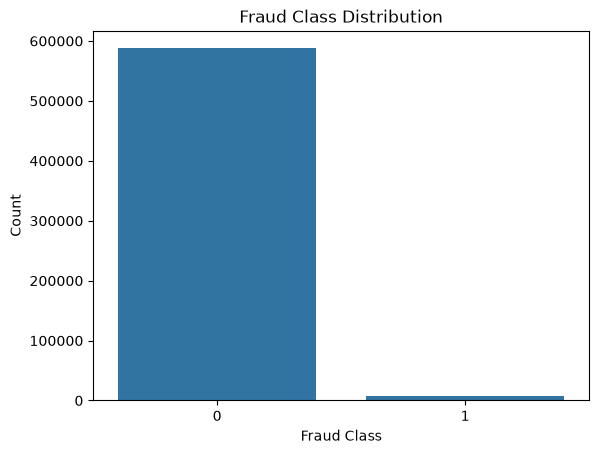

In [17]:
sns.countplot(x='fraud', data=df)
plt.title('Fraud Class Distribution')
plt.xlabel('Fraud Class')
plt.ylabel('Count')
plt.show()

**Interpretation**

Fraud represents only about 1.2% of the transactions, so the dataset is highly imbalanced.

Because of this, accuracy alone is not enough. I will focus on Precision, Recall, F1-score, Average Precision, ROC-AUC, and the confusion matrix.


### 5.2 Fraud Risk by Purchase Category

**Question:** Does fraud risk change across purchase categories?


In [18]:
category_counts=df['category'].value_counts()
category_counts

category
es_transportation        505119
es_food                   26254
es_health                 16133
es_wellnessandbeauty      15086
es_fashion                 6454
es_barsandrestaurants      6373
es_hyper                   6098
es_sportsandtoys           4002
es_tech                    2370
es_home                    1986
es_hotelservices           1744
es_otherservices            912
es_contents                 885
es_travel                   728
es_leisure                  499
Name: count, dtype: int64

In [19]:
df.query('fraud==1')['category'].value_counts()

category
es_sportsandtoys         1982
es_health                1696
es_wellnessandbeauty      718
es_travel                 578
es_hotelservices          548
es_leisure                474
es_home                   302
es_hyper                  280
es_otherservices          228
es_tech                   158
es_barsandrestaurants     120
es_fashion                116
Name: count, dtype: int64

In [20]:
category_fraud_rate_percent = df.groupby('category')['fraud'].mean().sort_values(ascending=False)*100
category_fraud_rate_percent

category
es_leisure               94.989980
es_travel                79.395604
es_sportsandtoys         49.525237
es_hotelservices         31.422018
es_otherservices         25.000000
es_home                  15.206445
es_health                10.512614
es_tech                   6.666667
es_wellnessandbeauty      4.759380
es_hyper                  4.591669
es_barsandrestaurants     1.882944
es_fashion                1.797335
es_contents               0.000000
es_food                   0.000000
es_transportation         0.000000
Name: fraud, dtype: float64

In [21]:
over_all_fraude_rate=df['fraud'].mean()*100
over_all_fraude_rate

np.float64(1.2108105199254007)

In [22]:
category_analysis=df.groupby('category').agg(
    total_transactions=('category','count'),
    fraud_transactions=('fraud','sum'),
    fraud_rate=('fraud','mean')
)
category_analysis['fraud_rate']=category_analysis['fraud_rate']*100
category_analysis=category_analysis.sort_values(by='fraud_rate',ascending=False)
category_analysis



,total_transactions,fraud_transactions,fraud_rate
category,,,
es_leisure,499,474,94.989980
es_travel,728,578,79.395604
es_sportsandtoys,4002,1982,49.525237
es_hotelservices,1744,548,31.422018
es_otherservices,912,228,25.000000
es_home,1986,302,15.206445
es_health,16133,1696,10.512614
es_tech,2370,158,6.666667
es_wellnessandbeauty,15086,718,4.759380


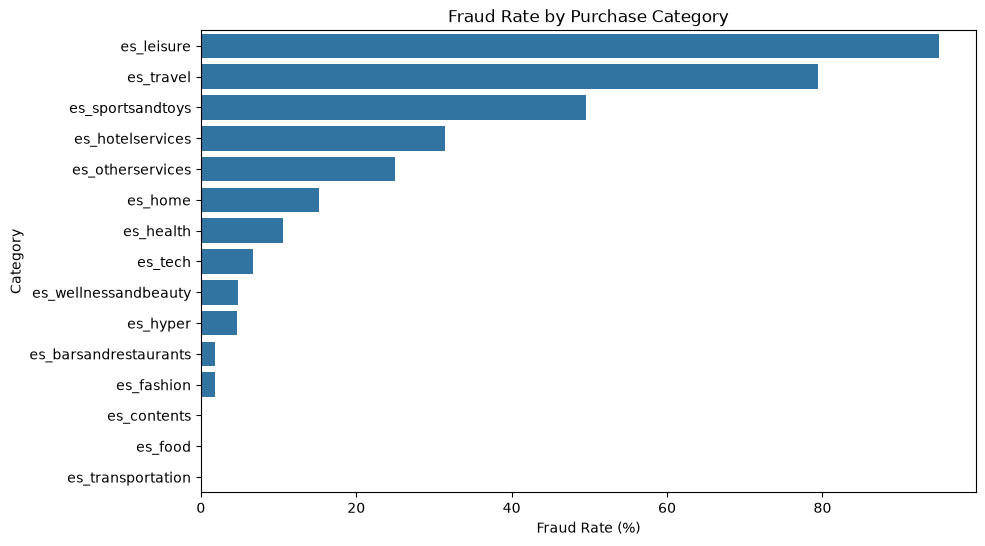

In [23]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=category_analysis.reset_index(),
    x='fraud_rate',
    y='category'
)

plt.title('Fraud Rate by Purchase Category')
plt.xlabel('Fraud Rate (%)')
plt.ylabel('Category')
plt.show()

In [24]:
category_analysis['fraud_lift']=(category_analysis['fraud_rate']/over_all_fraude_rate)
category_analysis

,total_transactions,fraud_transactions,fraud_rate,fraud_lift
category,,,,
es_leisure,499,474,94.989980,78.451565
es_travel,728,578,79.395604,65.572278
es_sportsandtoys,4002,1982,49.525237,40.902550
es_hotelservices,1744,548,31.422018,25.951227
es_otherservices,912,228,25.000000,20.647326
es_home,1986,302,15.206445,12.558897
es_health,16133,1696,10.512614,8.682295
es_tech,2370,158,6.666667,5.505954
es_wellnessandbeauty,15086,718,4.759380,3.930739


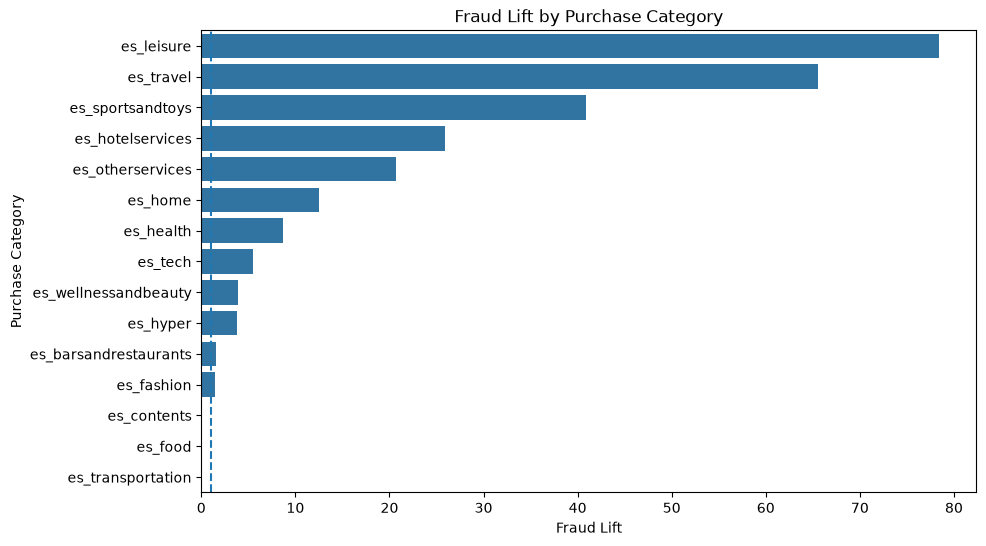

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis.reset_index(),
    x='fraud_lift',
    y='category'
)

plt.title('Fraud Lift by Purchase Category')
plt.xlabel('Fraud Lift')
plt.ylabel('Purchase Category')

plt.axvline(1, linestyle='--')

plt.show()

**Interpretation**

Fraud rate changes a lot between categories. Some categories are far above the overall fraud rate, so `category` looks useful for prediction.

The number of transactions also matters because a high rate from a very small group can be misleading.


### 5.3 Transaction Amount vs Fraud

**Question:** Are fraudulent transactions usually different in amount from benign transactions?


In [26]:
df.groupby('fraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud,,,,,,,,
0,587443.0,31.847230,31.470876,0.00,13.59,26.610,41.8950,2144.86
1,7200.0,530.926551,835.587112,0.03,159.98,319.175,548.9775,8329.96


#### Transaction Amount Distribution

Transaction amounts are strongly skewed, so `log(1 + amount)` is used only in this plot to make the two distributions easier to compare.


In [27]:
amount_plot = df[['fraud', 'amount']].copy()
amount_plot['log_amount'] = np.log1p(amount_plot['amount'])

fig = px.histogram(
    amount_plot,
    x='log_amount',
    color='fraud',
    histnorm='probability density',
    nbins=50,
    barmode='overlay',
    opacity=0.6,
    marginal='box',
    title='Transaction Amount Distribution by Fraud Class'
)

fig.update_layout(
    xaxis_title='Log(1 + Transaction Amount)',
    yaxis_title='Density'
)

fig.show()


**Interpretation**

Fraudulent transactions are generally much larger than benign transactions.

There is still overlap between the two groups, so `amount` is useful but cannot detect fraud by itself.


### 5.4 Fraud Risk by Merchant

**Question:** Do fraud rates differ across merchants?


In [28]:
merchant_analysis = df.groupby('merchant').agg(
    total_transactions=('fraud', 'count'),
    fraud_transactions=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

merchant_analysis['fraud_rate'] *= 100

merchant_analysis = merchant_analysis.sort_values(
    'fraud_rate',
    ascending=False
)

merchant_analysis.head(10)

,total_transactions,fraud_transactions,fraud_rate
merchant,,,
M1294758098,191,184,96.335079
M3697346,308,290,94.155844
M1873032707,250,216,86.400000
M732195782,608,518,85.197368
M980657600,1769,1472,83.210854
M1353266412,78,64,82.051282
M857378720,122,92,75.409836
M2080407379,48,36,75.000000
M2011752106,244,166,68.032787


In [29]:
top_merchants = merchant_analysis.head(10).reset_index()

fig = px.bar(
    top_merchants,
    x='fraud_rate',
    y='merchant',
    orientation='h',
    title='Top 10 Merchants by Observed Fraud Rate',
    hover_data=['total_transactions', 'fraud_transactions']
)

fig.update_layout(
    xaxis_title='Fraud Rate (%)',
    yaxis_title='Merchant',
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()

**Interpretation**

Some merchants have much higher observed fraud rates than others, so `merchant` may contain useful information.

This is only an association in the dataset and does not mean that a merchant causes fraud.


### 5.5 Correlation Between Numerical Features

**Question:** What linear relationships appear between the numerical variables?


In [30]:
numeric_cols = ['step', 'amount', 'fraud']

corr_matrix = df[numeric_cols].corr()

fig = px.imshow(
    corr_matrix,
    text_auto='.2f',
    aspect='auto',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    title='Correlation Matrix of Numerical Features'
)

fig.show()


**Interpretation**

`amount` has a moderate positive correlation with fraud, which matches the earlier amount analysis.

`step` has almost no linear correlation with fraud, but that does not automatically mean it is useless.


### 5.6 Fraud Risk by Age Group

**Question:** Does fraud risk differ across age groups?


In [31]:
age_analysis = df.groupby('age').agg(
    total_transactions=('fraud', 'count'),
    fraud_transactions=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

age_analysis['fraud_rate'] *= 100

age_analysis = age_analysis.sort_values(
    'fraud_rate',
    ascending=False
)

age_analysis

,total_transactions,fraud_transactions,fraud_rate
age,,,
0,2452,48,1.957586
4,109025,1410,1.293281
2,187310,2344,1.251401
3,147131,1755,1.192815
1,58131,689,1.185254
5,62642,686,1.095112
6,26774,261,0.974826
U,1178,7,0.594228


In [32]:
age_plot = age_analysis.reset_index()

fig = px.bar(
    age_plot,
    x='age',
    y='fraud_rate',
    hover_data=['total_transactions', 'fraud_transactions'],
    category_orders={'age': ['0', '1', '2', '3', '4', '5', '6', 'U']},
    title='Fraud Rate by Age Group'
)
fig.add_hline(
    y=over_all_fraude_rate,
    line_dash='dash',
    annotation_text='Overall Fraud Rate'
)

fig.update_layout(
    xaxis_title='Age Group',
    yaxis_title='Fraud Rate (%)'
)

fig.show()


**Interpretation**

Fraud rates differ somewhat across age groups, but the differences are smaller than what we saw for amount and category.


### 5.7 Fraud Risk by Gender

**Question:** Does fraud rate differ across gender categories?


In [33]:
gender_analysis = df.groupby('gender').agg(
    total_transactions=('fraud', 'count'),
    fraud_transactions=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

gender_analysis['fraud_rate'] *= 100

gender_analysis = gender_analysis.sort_values(
    'fraud_rate',
    ascending=False
)

gender_analysis

,total_transactions,fraud_transactions,fraud_rate
gender,,,
F,324565,4758,1.465962
M,268385,2435,0.907279
E,1178,7,0.594228
U,515,0,0.000000


In [34]:
gender_plot = gender_analysis.reset_index()

fig = px.bar(
    gender_plot,
    x='gender',
    y='fraud_rate',
    hover_data=['total_transactions', 'fraud_transactions'],
    title='Fraud Rate by Gender'
)

fig.add_hline(
    y=over_all_fraude_rate,
    line_dash='dash',
    annotation_text='Overall Fraud Rate'
)

fig.update_layout(
    xaxis_title='Gender Category',
    yaxis_title='Fraud Rate (%)'
)

fig.show()

**Interpretation**

Fraud rates are not exactly the same across gender categories.

These differences may add some predictive information, but they should not be interpreted as causal.


### 5.8 Temporal Fraud Patterns

**Question:** Does fraud activity change across the time steps?


In [35]:
step_analysis = df.groupby('step').agg(
    total_transactions=('fraud', 'count'),
    fraud_transactions=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
).reset_index()

step_analysis['fraud_rate'] *= 100

step_analysis.head()

,step,total_transactions,fraud_transactions,fraud_rate
0,0,2430,40,1.646091
1,1,2424,40,1.650165
2,2,2462,40,1.624695
3,3,2499,40,1.600640
4,4,2532,40,1.579779


In [36]:
fig = px.line(
    step_analysis,
    x='step',
    y='fraud_rate',
    title='Fraud Rate Across Time Steps'
)

fig.update_layout(
    xaxis_title='Time Step (Hour)',
    yaxis_title='Fraud Rate (%)'
)

fig.show()

In [37]:
fig = px.line(
    step_analysis,
    x='step',
    y=['total_transactions', 'fraud_transactions'],
    title='Transaction and Fraud Counts Across Time Steps'
)

fig.update_layout(
    xaxis_title='Time Step (Hour)',
    yaxis_title='Number of Transactions'
)

fig.show()

**Interpretation**

The fraud rate decreases over the observed steps, but the number of fraud transactions does not actually fall.

Total transaction volume grows faster than fraud volume, which explains the lower fraud rate.


### 5.9 Customer-Level Fraud Patterns

**Question:** Is fraud concentrated among some customers?


In [38]:
customer_analysis = df.groupby('customer').agg(
    total_transactions=('fraud', 'count'),
    fraud_transactions=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

customer_analysis['fraud_rate'] *= 100

customer_analysis = customer_analysis.sort_values(
    'fraud_transactions',
    ascending=False
)

customer_analysis.head(10)

,total_transactions,fraud_transactions,fraud_rate
customer,,,
C1350963410,191,144,75.392670
C1849046345,171,127,74.269006
C806399525,237,125,52.742616
C2004941826,126,119,94.444444
C1275518867,252,114,45.238095
C1978250683,265,110,41.509434
C381007057,100,89,89.000000
C1572610482,101,89,88.118812
C1817318774,112,87,77.678571


In [39]:
top_fraud_customers = (
    customer_analysis
    .sort_values('fraud_transactions', ascending=False)
    .head(10)
    .reset_index()
)

fig = px.bar(
    top_fraud_customers,
    x='fraud_transactions',
    y='customer',
    orientation='h',
    hover_data=['total_transactions', 'fraud_rate'],
    title='Top 10 Customers by Number of Fraud Transactions'
)

fig.update_layout(
    xaxis_title='Number of Fraud Transactions',
    yaxis_title='Customer',
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()

**Interpretation**

Some customer IDs have many more fraud transactions than others.

I keep this as an EDA finding, but I do not use the raw customer ID in the first models because it has many unique values and may encourage memorization.


### 5.10 Transaction Amount Outliers

**Question:** Are unusually large amounts associated with more fraud?


In [40]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 13.74
Q3: 42.54
IQR: 28.799999999999997
Lower Bound: -29.459999999999994
Upper Bound: 85.74


In [41]:
df['amount_outlier'] = df['amount'] > upper_bound

outlier_analysis = df.groupby('amount_outlier').agg(
    total_transactions=('fraud', 'count'),
    fraud_transactions=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

outlier_analysis['fraud_rate'] *= 100

outlier_analysis

,total_transactions,fraud_transactions,fraud_rate
amount_outlier,,,
False,568845,996,0.175092
True,25798,6204,24.048376


**Interpretation**

Large amount outliers have a much higher fraud rate than normal-sized transactions.

For that reason, I do not remove them. Instead, I later create an `amount_outlier` feature.


### 5.11 Merchant and Category Relationship

**Question:** Are merchants tied to specific purchase categories?


In [42]:
merchant_category_count = (
    df.groupby('merchant')['category']
      .nunique()
)

merchant_category_count.value_counts().sort_index()

category
1    50
Name: count, dtype: int64

**Interpretation**

Each merchant appears in only one transaction category.

This means `merchant` and `category` contain overlapping information, but both are kept because merchant identity may still add information inside a category.


### 5.12 Amount by Category and Fraud Status

**Question:** Within the same category, are fraudulent transactions still larger?


In [43]:
amount_category_analysis = (
    df.groupby(['category', 'fraud'])['amount']
      .median()
      .unstack()
)

amount_category_analysis.columns = [
    'median_amount_benign',
    'median_amount_fraud'
]

amount_category_analysis

,median_amount_benign,median_amount_fraud
category,,
es_barsandrestaurants,35.800,135.960
es_contents,38.430,NaN
es_fashion,54.870,224.685
es_food,33.475,NaN
es_health,89.110,353.365
es_home,97.710,391.670
es_hotelservices,100.385,382.490
es_hyper,35.415,163.785
es_leisure,73.310,300.590


In [44]:
plot_data = (
    amount_category_analysis
    .reset_index()
    .melt(
        id_vars='category',
        var_name='transaction_type',
        value_name='median_amount'
    )
)

fig = px.bar(
    plot_data,
    x='category',
    y='median_amount',
    color='transaction_type',
    barmode='group',
    title='Median Transaction Amount by Category and Fraud Status'
)

fig.update_layout(
    xaxis_title='Transaction Category',
    yaxis_title='Median Transaction Amount',
    xaxis_tickangle=-45
)

fig.show()

**Interpretation**

For categories that contain fraud, the median fraudulent amount is generally much higher than the benign median.

This shows that `amount` remains useful even after considering transaction category.


### 5.13 EDA Summary

The main findings are:

- Fraud is rare, so class imbalance must be handled carefully.
- `amount` is one of the clearest signals, but it is not enough by itself.
- Fraud risk changes strongly across `category` and `merchant`.
- Large amount outliers contain useful fraud information and should not simply be removed.
- `age` and `gender` show smaller differences.
- `step` shows a time pattern even though its linear correlation with fraud is small.
- Customer behavior is interesting, but the raw customer ID is not used directly in the first models.

These findings guide the feature engineering and model experiments below.


## 6. Feature Engineering and Data Split

Before training any model, I prepare the final features and split the data.

The training set is used to fit the models, the validation set is used to compare experiments and tune settings, and the test set is kept for the final evaluation only.


### 6.1 Separate Features and Target

The `amount_outlier` column created during EDA is removed here because it was calculated using the full dataset. It will be created again using the training data only.


In [45]:
X = df.drop(columns=['fraud', 'amount_outlier'])
y = df['fraud']

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (594643, 7)
y shape: (594643,)


### 6.2 Train, Validation, and Test Sets

`train_test_split` creates two sets at a time, so I use it twice in the same splitting stage.

The final split is:

- 64% Training
- 16% Validation
- 20% Test

`stratify` keeps almost the same fraud percentage in all sets.


In [46]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("\nFraud rate:")
print("Training:", y_train.mean() * 100)
print("Validation:", y_val.mean() * 100)
print("Test:", y_test.mean() * 100)


Training shape: (380571, 7)
Validation shape: (95143, 7)
Test shape: (118929, 7)

Fraud rate:
Training: 1.210812174338034
Validation: 1.21080899277929
Test: 1.2108064475443332


### 6.3 Remove Customer ID

`customer` is an ID with many unique values. I remove it because using the raw ID may make the model memorize customers instead of learning general fraud patterns.


In [47]:
X_train = X_train.drop(columns=['customer']).copy()
X_val = X_val.drop(columns=['customer']).copy()
X_test = X_test.drop(columns=['customer']).copy()


### 6.4 Amount Outlier Feature

The outlier threshold is calculated from the training data only. The same threshold is then applied to validation and test data.


In [48]:
Q1_train = X_train['amount'].quantile(0.25)
Q3_train = X_train['amount'].quantile(0.75)

IQR_train = Q3_train - Q1_train
amount_upper_bound = Q3_train + 1.5 * IQR_train

X_train['amount_outlier'] = (X_train['amount'] > amount_upper_bound).astype(int)
X_val['amount_outlier'] = (X_val['amount'] > amount_upper_bound).astype(int)
X_test['amount_outlier'] = (X_test['amount'] > amount_upper_bound).astype(int)

print("Amount upper bound:", amount_upper_bound)


Amount upper bound: 85.725


### 6.5 Time-Based Feature

The project description says that one `step` represents one hour.

I use `step % 24` to create the position inside each 24-step cycle. I keep the original `step` as well.


In [49]:
X_train['hour_cycle'] = X_train['step'] % 24
X_val['hour_cycle'] = X_val['step'] % 24
X_test['hour_cycle'] = X_test['step'] % 24

X_train[['step', 'hour_cycle']].head()


,step,hour_cycle
381009,121,1
302598,99,3
64364,24,0
444878,139,19
346533,111,15


## 6.6 Model Preprocessing

The model preprocessing is fitted on the training data only.

- Categorical features → One-Hot Encoding
- Numerical features → Standard Scaling
- `amount_outlier` → kept as 0/1

The same fitted preprocessor is then used for validation and test data.


In [50]:
categorical_features = [
    'age',
    'gender',
    'merchant',
    'category',
    'hour_cycle'
]

numerical_features = [
    'step',
    'amount'
]

binary_features = [
    'amount_outlier'
]

preprocessor = ColumnTransformer([
    (
        'categorical',
        OneHotEncoder(handle_unknown='ignore'),
        categorical_features
    ),
    (
        'numerical',
        StandardScaler(),
        numerical_features
    ),
    (
        'binary',
        'passthrough',
        binary_features
    )
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training data processed.")
print("Validation data processed.")
print("Test data processed.")


Training data processed.
Validation data processed.
Test data processed.


## 7. Model Experiments

Several models are trained and compared on the validation set.

Because the dataset is highly imbalanced, F1-score is used as the main model-selection metric. Precision, Recall, and the Confusion Matrix are also reported.

The test set is not used during model selection.


### 7.1 Evaluation Function

The same evaluation function is used for every model.


In [51]:
results = []

def evaluate_model(model_name, y_true, y_pred):
    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred
    )

    print("Model:", model_name)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-score:", f1)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    return {
        'Model': model_name,
        'Precision': precision,
        'Recall': recall,
        'F1': f1
    }


### 7.2 Experiment 1 — Logistic Regression + Class Weight

`class_weight='balanced'` gives more importance to the rare fraud class.


In [52]:
logistic_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

y_pred_logistic = logistic_model.predict(
    X_val_processed
)

logistic_result = evaluate_model(
    'Logistic + Class Weight',
    y_val,
    y_pred_logistic
)

results.append(logistic_result)


Model: Logistic + Class Weight
Precision: 0.27107007575757575
Recall: 0.9939236111111112
F1-score: 0.4259672619047619

Confusion Matrix:
[[90912  3079]
 [    7  1145]]


### 7.3 Experiment 2 — Logistic Regression + SMOTENC

SMOTENC creates synthetic examples for the minority class while respecting categorical features.

It is applied only to the training data.


In [53]:
smote_categorical_features = (
    categorical_features + binary_features
)

smote_nc = SMOTENC(
    categorical_features=smote_categorical_features,
    random_state=42
)

X_train_smote, y_train_smote = smote_nc.fit_resample(
    X_train,
    y_train
)

X_train_smote_processed = preprocessor.transform(
    X_train_smote
)

logistic_smote_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_smote_model.fit(
    X_train_smote_processed,
    y_train_smote
)

y_pred_logistic_smote = logistic_smote_model.predict(
    X_val_processed
)

logistic_smote_result = evaluate_model(
    'Logistic + SMOTENC',
    y_val,
    y_pred_logistic_smote
)

results.append(logistic_smote_result)


Model: Logistic + SMOTENC
Precision: 0.30305466237942125
Recall: 0.9817708333333334
F1-score: 0.4631449631449631

Confusion Matrix:
[[91390  2601]
 [   21  1131]]


### 7.4 Experiment 3 — Random Forest

Random Forest can learn non-linear relationships between the features.

`balanced_subsample` helps the model pay more attention to the minority class.


In [54]:
random_forest_model = RandomForestClassifier(
    n_estimators=150,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_processed,
    y_train
)

y_pred_rf = random_forest_model.predict(
    X_val_processed
)

rf_result = evaluate_model(
    'Random Forest',
    y_val,
    y_pred_rf
)

results.append(rf_result)


Model: Random Forest
Precision: 0.873
Recall: 0.7578125
F1-score: 0.8113382899628253

Confusion Matrix:
[[93864   127]
 [  279   873]]


### 7.5 Experiment 4 — Gradient Boosting

Gradient Boosting builds trees sequentially, where each new tree tries to improve the previous mistakes.


In [55]:
gradient_boosting_model = GradientBoostingClassifier(
    random_state=42
)

gradient_boosting_model.fit(
    X_train_processed,
    y_train
)

y_pred_gradient = gradient_boosting_model.predict(
    X_val_processed
)

gradient_result = evaluate_model(
    'Gradient Boosting',
    y_val,
    y_pred_gradient
)

results.append(gradient_result)


Model: Gradient Boosting
Precision: 0.878727634194831
Recall: 0.7673611111111112
F1-score: 0.8192771084337349

Confusion Matrix:
[[93869   122]
 [  268   884]]


### 7.6 Experiment 5 — CatBoost

CatBoost can work directly with categorical features, so it is trained on the prepared DataFrame without One-Hot Encoding.

Built-in class weighting is used for the imbalanced target.


In [56]:
catboost_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.08,
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

catboost_model.fit(
    X_train,
    y_train,
    cat_features=categorical_features
)

y_pred_catboost = catboost_model.predict(
    X_val
).astype(int).ravel()

catboost_result = evaluate_model(
    'CatBoost',
    y_val,
    y_pred_catboost
)

results.append(catboost_result)


Model: CatBoost
Precision: 0.37683578104138854
Recall: 0.9800347222222222
F1-score: 0.5443587270973963

Confusion Matrix:
[[92124  1867]
 [   23  1129]]


### 7.7 Compare Baseline Models

The baseline models are sorted by validation F1-score.


In [57]:
results_df = pd.DataFrame(results)

results_df = (
    results_df
    .drop_duplicates(subset='Model', keep='last')
    .sort_values('F1', ascending=False)
    .reset_index(drop=True)
)

results_df


,Model,Precision,Recall,F1
0,Gradient Boosting,0.878728,0.767361,0.819277
1,Random Forest,0.873000,0.757812,0.811338
2,CatBoost,0.376836,0.980035,0.544359
3,Logistic + SMOTENC,0.303055,0.981771,0.463145
4,Logistic + Class Weight,0.271070,0.993924,0.425967


## 8. Hyperparameter Tuning

The strongest candidate models are tuned before final selection.

`RandomizedSearchCV` is used with F1-score as the optimization metric. The validation set remains separate from the cross-validation performed inside the training data.


### 8.1 Random Forest Tuning


In [58]:
rf_tuning_model = RandomForestClassifier(
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf_params = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

rf_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=rf_params,
    n_iter=10,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(
    X_train_processed,
    y_train
)

print("Best Parameters:")
print(rf_search.best_params_)

best_rf = rf_search.best_estimator_


Best Parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20, 'bootstrap': False}


In [59]:
y_pred_rf_tuned = best_rf.predict(
    X_val_processed
)

rf_tuned_result = evaluate_model(
    'Random Forest Tuned',
    y_val,
    y_pred_rf_tuned
)

results.append(rf_tuned_result)


Model: Random Forest Tuned
Precision: 0.38326446280991733
Recall: 0.9661458333333334
F1-score: 0.5488165680473372

Confusion Matrix:
[[92200  1791]
 [   39  1113]]


### 8.2 CatBoost Tuning

CatBoost is also tuned because it is a useful candidate for imbalanced classification.


In [60]:
catboost_tuning_model = CatBoostClassifier(
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

catboost_params = {
    'iterations': [200, 300, 400],
    'depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1]
}

catboost_search = RandomizedSearchCV(
    estimator=catboost_tuning_model,
    param_distributions=catboost_params,
    n_iter=8,
    scoring='f1',
    cv=3,
    random_state=42
)

cat_feature_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_features
]

catboost_search.fit(
    X_train,
    y_train,
    cat_features=cat_feature_indices
)

print("Best Parameters:")
print(catboost_search.best_params_)

best_catboost = catboost_search.best_estimator_


Best Parameters:
{'learning_rate': 0.1, 'iterations': 400, 'depth': 6}


In [61]:
y_pred_catboost_tuned = best_catboost.predict(
    X_val
).astype(int).ravel()

catboost_tuned_result = evaluate_model(
    'CatBoost Tuned',
    y_val,
    y_pred_catboost_tuned
)

results.append(catboost_tuned_result)


Model: CatBoost Tuned
Precision: 0.4112665684830633
Recall: 0.9696180555555556
F1-score: 0.577559462254395

Confusion Matrix:
[[92392  1599]
 [   35  1117]]


### 8.3 Gradient Boosting Tuning

Gradient Boosting was one of the strongest baseline models, so it is also tuned before selecting the final model.


In [62]:
gb_tuning_model = GradientBoostingClassifier(
    random_state=42
)

gb_params = {
    'n_estimators': [50, 80, 100, 150],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'min_samples_split': [2, 5, 10]
}

gb_search = RandomizedSearchCV(
    estimator=gb_tuning_model,
    param_distributions=gb_params,
    n_iter=10,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1
)

gb_search.fit(
    X_train_processed,
    y_train
)

print("Best Parameters:")
print(gb_search.best_params_)

best_gb = gb_search.best_estimator_


Best Parameters:
{'n_estimators': 150, 'min_samples_split': 10, 'max_depth': 3, 'learning_rate': 0.1}


In [63]:
y_pred_gb_tuned = best_gb.predict(
    X_val_processed
)

gb_tuned_result = evaluate_model(
    'Gradient Boosting Tuned',
    y_val,
    y_pred_gb_tuned
)

results.append(gb_tuned_result)


Model: Gradient Boosting Tuned
Precision: 0.881592039800995
Recall: 0.7690972222222222
F1-score: 0.8215113583681039

Confusion Matrix:
[[93872   119]
 [  266   886]]


## 9. Final Model Selection

All baseline and tuned models are compared using validation F1-score.

In the current experiments, Tuned Gradient Boosting achieved the highest validation F1-score, so it is selected as the Version 1 final model.


In [64]:
results_df = pd.DataFrame(results)

results_df = (
    results_df
    .drop_duplicates(subset='Model', keep='last')
    .sort_values('F1', ascending=False)
    .reset_index(drop=True)
)

results_df.to_csv(
    'model_results.csv',
    index=False
)

results_df


,Model,Precision,Recall,F1
0,Gradient Boosting Tuned,0.881592,0.769097,0.821511
1,Gradient Boosting,0.878728,0.767361,0.819277
2,Random Forest,0.873000,0.757812,0.811338
3,CatBoost Tuned,0.411267,0.969618,0.577559
4,Random Forest Tuned,0.383264,0.966146,0.548817
5,CatBoost,0.376836,0.980035,0.544359
6,Logistic + SMOTENC,0.303055,0.981771,0.463145
7,Logistic + Class Weight,0.271070,0.993924,0.425967


In [65]:
final_model = best_gb

print("Selected final model: Gradient Boosting Tuned")
print(
    "Best validation F1:",
    results_df.loc[
        results_df['Model'] == 'Gradient Boosting Tuned',
        'F1'
    ].iloc[0]
)


Selected final model: Gradient Boosting Tuned
Best validation F1: 0.8215113583681039


## 10. Final Test Evaluation

The test set has not been used for model comparison or hyperparameter tuning.

The selected Tuned Gradient Boosting model is evaluated here once on the unseen test set.


In [66]:
final_pred = final_model.predict(
    X_test_processed
)

final_test_result = evaluate_model(
    'Final Gradient Boosting Tuned',
    y_test,
    final_pred
)

final_test_df = pd.DataFrame(
    [final_test_result]
)

final_test_df


Model: Final Gradient Boosting Tuned
Precision: 0.8635294117647059
Recall: 0.7645833333333333
F1-score: 0.8110497237569061

Confusion Matrix:
[[117315    174]
 [   339   1101]]


,Model,Precision,Recall,F1
0,Final Gradient Boosting Tuned,0.863529,0.764583,0.81105


**Interpretation**

- Precision tells us how many transactions predicted as fraud were actually fraud.
- Recall tells us how many real fraud transactions were detected.
- F1-score summarizes the balance between Precision and Recall.
- The Confusion Matrix shows correct predictions, false alarms, and missed fraud cases.

The final reported project result should come from this test evaluation, while the validation F1-score is used for model selection.


## 11. Feature Importance

Because the final model is Gradient Boosting, its built-in feature importance is used.

The transformed feature names are taken from the fitted preprocessing step.


In [67]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

feature_importance.head(15)


,Feature,Importance
0,numerical__amount,0.646833
1,categorical__merchant_M980657600,0.048926
2,categorical__merchant_M480139044,0.042666
3,categorical__merchant_M1053599405,0.026491
4,numerical__step,0.018835
5,categorical__merchant_M1198415165,0.018151
6,categorical__category_es_leisure,0.018075
7,categorical__merchant_M1913465890,0.017203
8,categorical__merchant_M1873032707,0.011635
9,categorical__category_es_sportsandtoys,0.011316


In [68]:
top_features = feature_importance.head(15)

fig = px.bar(
    top_features,
    x='Importance',
    y='Feature',
    orientation='h',
    title='Top 15 Feature Importances'
)

fig.update_layout(
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()


## 12. Business Recommendations

Based on the EDA and the final model:

- Use the model as a fraud-screening tool to identify transactions that deserve additional review.
- Large transaction amounts should not simply be removed because they contain useful fraud information.
- Category and merchant patterns can help identify higher-risk transaction groups.
- False positives and missed fraud cases should both be monitored when the model is used in practice.
- The model should be re-evaluated over time because transaction and fraud patterns may change.
- Merchant and demographic patterns should be treated as associations, not proof of causation.


## 13. Save Final Model

The Version 1 final model, fitted preprocessor, and the training-only amount-outlier threshold are saved together.

These objects will be used by the FastAPI application.


In [69]:
final_test_df.to_csv(
    'final_test_results.csv',
    index=False
)

model_package = {
    'model': final_model,
    'preprocessor': preprocessor,
    'amount_upper_bound': amount_upper_bound,
    'categorical_features': categorical_features,
    'numerical_features': numerical_features,
    'binary_features': binary_features,
    'model_feature_columns': X_train.columns.tolist()
}

with open(
    'fraud_detection_model.pkl',
    'wb'
) as file:
    pickle.dump(model_package, file)

print("Final model package saved.")


Final model package saved.


## 14. Check the Saved Model

This confirms that the Pickle file can be loaded and used again.


In [70]:
with open(
    'fraud_detection_model.pkl',
    'rb'
) as file:
    loaded_package = pickle.load(file)

loaded_model = loaded_package['model']
loaded_preprocessor = loaded_package['preprocessor']

sample_data = X_test.head(5)

sample_processed = loaded_preprocessor.transform(
    sample_data
)

loaded_predictions = loaded_model.predict(
    sample_processed
)

pd.DataFrame({
    'Prediction': loaded_predictions
})


,Prediction
0,0
1,0
2,0
3,0
4,0


## 15. Final Project Checklist

The notebook now includes:

- Data understanding and cleaning
- Exploratory Data Analysis
- Feature engineering
- Train / validation / test split
- One-Hot Encoding and Standard Scaling
- Class imbalance handling
- Logistic Regression + Class Weight
- Logistic Regression + SMOTENC
- Random Forest
- Gradient Boosting
- CatBoost
- Validation comparison using F1-score
- Hyperparameter tuning for Random Forest, CatBoost, and Gradient Boosting
- Final model selection
- Final test evaluation
- Native feature importance for the final Gradient Boosting model
- Business recommendations
- Saving the final model package with Pickle


